In [6]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

In [7]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
model = models[1]
plotdir = '/home/kperny/VolMIP_stratosphere/plots/compare_weierbach2023/'

enso_nao_flags_pi = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags_pi = enso_nao_flags_pi.set_index(['model', 'realization']).loc[model]

enso_nao_flags_volc = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
enso_nao_flags_volc = enso_nao_flags_volc.set_index(['model', 'realization']).loc[model].where(enso_nao_flags_volc['experiment']=='volc').dropna()

nao_volc = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_change.csv")
nao_volc = nao_volc.set_index(['model', 'realization']).loc[model]
enso_nao_flags_pi['nao_flag_volc'] = nao_volc.where(nao_volc['experiment']=='volc').dropna().loc[enso_nao_flags_pi.index].nao_flag.values

In [8]:
ta_volc = load_data(path + model + '/ta_AmonZ_*fixed_dates.nc').sel(time=slice('1991-12','1992-02')).mean('time').squeeze()
ua_volc = load_data(path + model + '/ua_AmonZ_*fixed_dates.nc').sel(time=slice('1991-12','1992-02')).mean('time').squeeze()

ua_clim_pi = xr.open_dataset(glob.glob(path_piControl + model + '/ta_clim-djf*')[0]).squeeze()
ta_clim_pi = load_climatology(glob.glob(path_piControl + model + '/ta_clim-djf*')[0]).squeeze()

ta_piControl = calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/ta_AmonZ*.nc')[0], decode_times=time_coder))
ua_piControl = calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/ua_AmonZ*.nc')[0], decode_times=time_coder))

ta_volc_clim = ta_piControl.sel(time=enso_nao_flags_pi['year'].values)
ta_volc_clim['time'] = enso_nao_flags_pi.index.values
ta_volc_clim = ta_volc_clim.rename({'time': 'ens'}).squeeze()

ua_volc_clim = ua_piControl.sel(time=enso_nao_flags_pi['year'].values)
ua_volc_clim['time'] = enso_nao_flags_pi.index.values
ua_volc_clim = ua_volc_clim.rename({'time': 'ens'}).squeeze()

/tmp/ipykernel_626765/1181899298.py:35: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(xr.open_dataset(p))
/tmp/ipykernel_626765/1181899298.py:35: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(xr.open_dataset(p))
/tmp/ipykernel_626765/1181899298.py:35: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(xr.open_dataset(p))
/tmp/ipyke

In [9]:
ta_volc_gradient = ta_volc.sel(plev=5000, lat=0, method='nearest') -  ta_volc.sel(plev=5000, lat=90, method='nearest')
ta_clim_gradient = ta_piControl.sel(plev=5000, lat=0, method='nearest') -  ta_piControl.sel(plev=5000, lat=90, method='nearest')
ta_volc_clim_gradient = ta_volc_clim.sel(plev=5000, lat=0, method='nearest') -  ta_volc_clim.sel(plev=5000, lat=90, method='nearest')

ta_ano_paired_gradient = ta_volc_gradient - ta_volc_clim_gradient
ta_ano_clim_gradient = ta_volc_gradient - ta_clim_gradient.mean('time').squeeze()

ua_ano_paired = ua_volc - ua_volc_clim
ua_ano_clim = ua_volc - ua_piControl.mean('time')

In [10]:
enso_nao_flags_pi['DeltaT_paired'] = ta_ano_paired_gradient.sel(ens=enso_nao_flags_pi.index).ta.values
enso_nao_flags_pi['DeltaU_paired'] = ua_ano_paired.sel(lat=60, plev=1000, method='nearest').squeeze().sel(ens=enso_nao_flags_pi.index).ua.values
enso_nao_flags_pi['DeltaT_clim'] = ta_ano_clim_gradient.sel(ens=enso_nao_flags_pi.index).ta.values
enso_nao_flags_pi['DeltaU_clim'] = ua_ano_clim.sel(lat=60, plev=1000, method='nearest').sel(ens=enso_nao_flags_pi.index).squeeze().ua.values

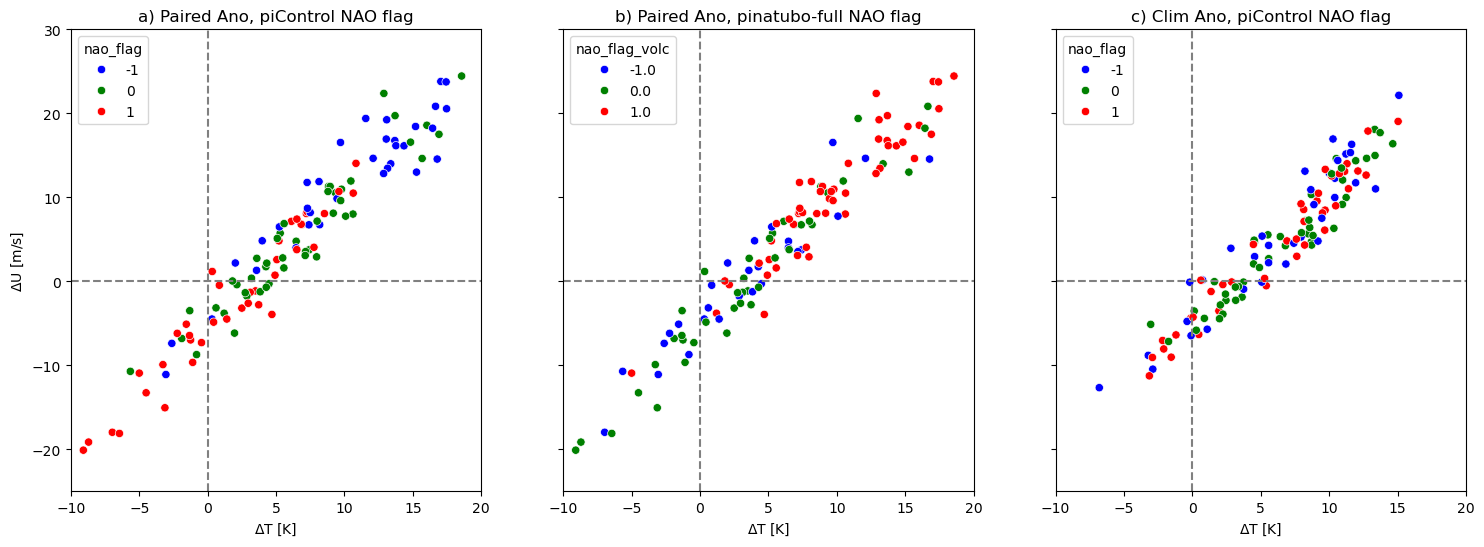

In [14]:
fig, axs = plt.subplots(1,3, figsize=(18,6), sharey=True)

sns.scatterplot(enso_nao_flags_pi, x='DeltaT_paired', y='DeltaU_paired', hue='nao_flag', palette=['blue', 'green', 'red'], ax=axs[0])
sns.scatterplot(enso_nao_flags_pi, x='DeltaT_paired', y='DeltaU_paired', hue='nao_flag_volc', palette=['blue', 'green', 'red'], ax=axs[1])
sns.scatterplot(enso_nao_flags_pi, x='DeltaT_clim', y='DeltaU_clim', hue='nao_flag', palette=['blue', 'green', 'red'], ax=axs[2])

axs[0].set_title('a) Paired Ano, piControl NAO flag')
axs[1].set_title('b) Paired Ano, pinatubo-full NAO flag')
axs[2].set_title('c) Clim Ano, piControl NAO flag')

axs[0].set_ylabel('$\Delta$U [m/s]')
for ax in axs:
    ax.hlines(0, -10, 20, colors='grey', linestyles='dashed')
    ax.vlines(0, -25, 30, colors='grey', linestyles='dashed')
    ax.set_ylim(-25,30)
    ax.set_xlim(-10,20)
    ax.set_xlabel('$\Delta$T [K]')

plt.savefig(plotdir + 'comparision_figure4.png', dpi=200)